# 05．Event Engine：把資源時序接到 Tag 狀態

本單元使用 03 的 ResourceTimeline 與 04 的電量規則。整數 ns 事件佇列一次處理一組同時事件。
先批次收集 D2R 完成、再更新資源邊界，最後處理新操作；Deadline 仍為嚴格的 `<`。
RF、Paging／等待與接收結果均是明列輸入。這裡沒有 Baseline、服務記帳或硬體校準。


## 1．重用 03 與 04，不重跑它們的展示

04 核心尚未抽離；此處只載入標示 definitions 的程式區塊。模組保留在本 kernel，讓不可變資料類別可正常運作。


In [1]:
from pathlib import Path
import sys
import json
import types
import heapq
from dataclasses import dataclass
from decimal import Decimal

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent

if not (ROOT / 'src').is_dir():
    raise ValueError('Run from the project root or notebooks directory')

if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from timeline.contracts import ResourceConfig, UEDirection
from timeline.resource_timeline import build_timeline

energy = types.ModuleType('event_engine_energy')
sys.modules[energy.__name__] = energy
energy_notebook = json.loads((ROOT / 'notebooks/04_tag_energy.ipynb').read_text())
for index, cell in enumerate(energy_notebook['cells']):
    if cell['cell_type'] == 'code' and 'definitions' in cell['metadata'].get('tags', []):
        exec(compile(''.join(cell['source']), f'04:definitions-{index}', 'exec'), energy.__dict__)


## 2．整數 ns 的同時事件批次

`heapq` 只管理時間與插入序號；插入序號不決定資料資格。同一時間的事件會一次取出。
過去時間、bool 或非整數時間會在插入前拒絕。


In [2]:
@dataclass(frozen=True)
class Event:
    time_ns: int
    kind: str
    payload: object


class EventQueue:
    def __init__(self):
        self.now_ns = 0
        self._events = []
        self._sequence = 0

    def schedule(self, time_ns, kind, payload=None):
        if type(time_ns) is not int or time_ns < 0:
            raise ValueError('event time must be nonnegative integer ns')

        if time_ns < self.now_ns:
            raise ValueError('cannot schedule an event in the past')

        if not isinstance(kind, str) or not kind.strip():
            raise ValueError('event kind must be a nonempty string')

        event = Event(time_ns, kind, payload)
        heapq.heappush(self._events, (time_ns, self._sequence, event))
        self._sequence += 1

    def peek_time(self):
        return self._events[0][0] if self._events else None

    def pop_batch(self):
        if not self._events:
            return None
        self.now_ns = self._events[0][0]
        events = []
        while self._events and self._events[0][0] == self.now_ns:
            events.append(heapq.heappop(self._events)[2])
        return self.now_ns, tuple(events)


## 3．環境狀態與電量推進

每次先結算舊 phase 的電量，再批次收集完成、更新資源及處理新請求。
操作計畫可保存未來區段，但目前快照只使用當下時間插值，不提前扣完整筆電量。
完整電量仍在啟動前檢查；同一 Tag 的同時衝突請求整組拒絕。CW 條件由外部提供。


In [3]:
@dataclass(frozen=True)
class OperationRequest:
    start_ns: int
    tag_id: str
    window_id: int
    tbs_bytes: int
    paging_ns: int
    wait_ns: int
    deadline_ns: int
    receive_success: bool = True
    cw_available: bool = True

    def __post_init__(self):
        if not isinstance(self.tag_id,str) or not self.tag_id.strip():
            raise ValueError('tag_id must be a nonempty string')

        energy._nonnegative_ns(self.window_id,'window_id')
        energy._nonnegative_ns(self.start_ns,'start_ns')


class TagEventEngine:
    """Private environment calendar; selected operations come from external Access inputs."""
    def __init__(self, windows, snapshots, tag_nodes, rf_inputs_w, requests=()):
        self.windows = tuple(windows)
        self.snapshots = dict(snapshots)
        self.tag_nodes = dict(tag_nodes)
        self.rf_inputs_w = dict(rf_inputs_w)
        self.queue = EventQueue()
        self.now_ns = 0
        self.trace = []
        self.completion_batches = []
        self.energy_history = []
        self.active = {}
        self.resources = {}
        self.phases = {}
        self.current_windows = {}
        if not self.windows or not self.snapshots or set(self.snapshots) != set(self.tag_nodes):
            raise ValueError('nonempty windows and matching Tag inputs are required')

        node_ids = {node.node_id for window in self.windows for node in window.nodes}
        if not set(self.tag_nodes.values()) <= node_ids:
            raise ValueError('unknown serving Node')

        self.phases = {node:'GAP' for node in node_ids}
        self.current_windows = {node:None for node in node_ids}
        for tag_id, snapshot in self.snapshots.items():
            energy._validate_snapshot(snapshot, energy._trace_settings(energy.energy_settings))
            if snapshot.tag_id != tag_id or snapshot.now_ns != 0 or snapshot.mode not in energy.INACTIVE_MODES:
                raise ValueError('initial snapshots must match IDs, be inactive and start at zero')

        previous_end = -1
        for window in self.windows:
            if window.start_ns < previous_end:
                raise ValueError('Windows must be ordered without overlap')
            previous_end = window.end_ns
            for node in window.nodes:
                if not node.start_ns < node.ue_end_ns < node.ue_end_ns+1_000_000 < node.end_ns:
                    raise ValueError('resource must contain UE, switch and Tag intervals')
                self.resources[(node.window_id,node.node_id)] = node
                for tag_id, owner in self.tag_nodes.items():
                    if owner == node.node_id:
                        key = (node.window_id,tag_id)
                        if key not in self.rf_inputs_w:
                            raise ValueError('missing per-Tag/window RF input')
                        energy._energy_decimal(self.rf_inputs_w[key], 'rf_input_w')
                for time_ns, kind in ((node.start_ns,'WINDOW_START'),(node.ue_end_ns,'UE_END'),
                                      (node.ue_end_ns+1_000_000,'SWITCH_END'),(node.end_ns,'WINDOW_END')):
                    self.queue.schedule(time_ns,kind,node)
        for request in requests:
            if not isinstance(request,OperationRequest):
                raise ValueError('requests must be OperationRequest values')
            self.queue.schedule(request.start_ns,'REQUEST',request)

    def _advance(self, time_ns):
        for tag_id, snapshot in self.snapshots.items():
            if tag_id in self.active:
                plan = self.active[tag_id]
                if time_ns >= plan.snapshot.now_ns:
                    updated = plan.snapshot
                else:
                    row = next(row for row in plan.rows if row.start_ns <= time_ns < row.end_ns)
                    elapsed = Decimal(time_ns-row.start_ns)/Decimal(row.end_ns-row.start_ns)
                    stored = Decimal(str(row.before_j))-Decimal(str(row.consumed_j))*elapsed
                    updated = energy.TagSnapshot(tag_id,time_ns,energy._trace_float(stored),row.mode)
                self.snapshots[tag_id] = updated
            else:
                node_id = self.tag_nodes[tag_id]
                window_id = self.current_windows[node_id]
                rf = self.rf_inputs_w[(window_id,tag_id)] if self.phases[node_id] in ('UE_UL','UE_DL') else 0
                result = energy.advance_tag_interval(snapshot,duration_ns=time_ns-snapshot.now_ns,
                                                     phase=self.phases[node_id],rf_input_w=rf)
                self.snapshots[tag_id] = result.snapshot
        self.now_ns = time_ns
        self.queue.now_ns = time_ns
        for tag_id, snapshot in self.snapshots.items():
            self.energy_history.append(dict(time_ns=time_ns,tag_id=tag_id,
                                            mode=snapshot.mode.value,energy_j=snapshot.energy_j))

    def _record(self, kind, tag_id=None, outcome='', **fields):
        row = dict(time_ns=self.now_ns,kind=kind,tag_id=tag_id,outcome=outcome,**fields)
        self.trace.append(row)

    def _request(self, request):
        tag_id = request.tag_id
        try:
            if tag_id not in self.snapshots:
                raise ValueError('unknown Tag')

            node_id = self.tag_nodes[tag_id]
            key = (request.window_id,node_id)
            if key not in self.resources or self.current_windows[node_id] != request.window_id:
                raise ValueError('operation Window is not current')

            node = self.resources[key]
            if self.now_ns < node.ue_end_ns+1_000_000 or self.now_ns >= node.end_ns:
                raise ValueError('operation starts outside Tag availability')

            if tag_id in self.active:
                raise ValueError('Tag already has an active operation')

            plan = energy.trace_tag_operation(self.snapshots[tag_id],tbs_bytes=request.tbs_bytes,
                        paging_ns=request.paging_ns,wait_ns=request.wait_ns,window_end_ns=node.end_ns,
                        deadline_ns=request.deadline_ns,receive_success=request.receive_success,cw_available=request.cw_available)
        except ValueError as error:
            self._record('REJECTED',tag_id,str(error))
            return
        self.active[tag_id] = plan
        self._record('WAKING',tag_id,'admitted; activation charged once')
        for row in plan.rows:
            kind = {'PAGING':'PAGING_END','WAIT_D2R':'WAIT_END','D2R':'D2R_END','GUARD':'GUARD_END'}.get(row.phase)
            if kind is not None:
                self.queue.schedule(row.end_ns,kind,request)
        self._advance(self.now_ns)

    def run_until(self, until_ns):
        if type(until_ns) is not int or until_ns < self.now_ns:
            raise ValueError('until_ns must be integer ns at or after the current time')

        while self.queue.peek_time() is not None and self.queue.peek_time() <= until_ns:
            time_ns, events = self.queue.pop_batch()
            self._advance(time_ns)
            completed = []
            for event in events:
                if event.kind == 'D2R_END':
                    request = event.payload
                    completed.append(dict(tag_id=request.tag_id,receive_success=request.receive_success,
                                          eligible=request.receive_success and time_ns < request.deadline_ns))
            if completed:
                completed.sort(key=lambda row:row['tag_id'])
                self.completion_batches.append((time_ns,tuple(completed)))
                for result in completed:
                    self._record('D2R_END',**result)
            for event in events:
                if event.kind in ('WINDOW_START','UE_END','SWITCH_END','WINDOW_END'):
                    node = event.payload
                    if event.kind=='WINDOW_START':
                        self.current_windows[node.node_id] = node.window_id
                        self.phases[node.node_id] = 'UE_UL' if node.direction is UEDirection.UL else 'UE_DL'
                    elif event.kind=='UE_END':
                        self.phases[node.node_id] = 'RF_SWITCH'
                    elif event.kind=='SWITCH_END':
                        self.phases[node.node_id] = 'WAIT_D2R'
                    else:
                        self.phases[node.node_id] = 'GAP'
                        self.current_windows[node.node_id] = None
                    self._record(event.kind,node_id=node.node_id,window_id=node.window_id)
                elif event.kind=='GUARD_END':
                    self.active.pop(event.payload.tag_id)
                    self._record('GUARD_END',event.payload.tag_id)
                elif event.kind in ('PAGING_END','WAIT_END','OBSERVE'):
                    self._record(event.kind)
            requests = [event.payload for event in events if event.kind == 'REQUEST']
            for request in requests:
                count = sum(other.tag_id == request.tag_id for other in requests)
                if count > 1:
                    self._record('REJECTED',request.tag_id,'simultaneous requests conflict for this Tag')
                else:
                    self._request(request)
        self._advance(until_ns)
        return dict(self.snapshots)


## 4．明列情境：跨窗口、平行回傳與中途觀察

沿用 03 的產生器；窗口起點改用已確認的 0／1 s，保留 600 ms 窗口與 400 ms 空檔。
每個 Tag／窗口的 RF 是明列的 1 μW 輸入，不表示已實作來源功率／通道 adapter。
同批展示使用相同 TBS、相同回應起點及各自正交資源；正式 CFA／SFS 排程仍由 Access 提供。


In [4]:
from IPython.display import HTML, Image, display
from html import escape
from io import BytesIO
import matplotlib.pyplot as plt


def display_rows(rows):
    columns = tuple(rows[0]) if rows else ()
    header = ''.join('<th>'+escape(str(name))+'</th>' for name in columns)
    body = ''
    for row in rows:
        body += '<tr>'+''.join('<td>'+escape(str(row.get(name,'')))+'</td>' for name in columns)+'</tr>'
    display(HTML('<table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table>'))

resource_config = ResourceConfig('event-engine-demo',42,('N1',),(0,1_000_000_000))
windows = build_timeline(resource_config)
display_rows([dict(window_id=window.window_id,direction=node.direction.value,
                   start_ms=node.start_ns/1e6,ue_end_ms=node.ue_end_ns/1e6,
                   switch_end_ms=(node.ue_end_ns+1_000_000)/1e6,end_ms=node.end_ns/1e6)
              for window in windows for node in window.nodes])

# Initialization is full only once; later Windows do not reset these snapshots.
initial_snapshots = {tag:energy.TagSnapshot(tag,0,1e-6,energy.TagMode.STATIC) for tag in ('Tag-001','Tag-002')}
tag_nodes = {tag:'N1' for tag in initial_snapshots}
rf_inputs_w = {(window.window_id,tag):1e-6 for window in windows for tag in initial_snapshots}
operation_start_ns = windows[0].nodes[0].ue_end_ns+1_000_000
requests = (
    OperationRequest(operation_start_ns,'Tag-001',0,16,2_000_000,1_000_000,20_000_000_000,True),
    OperationRequest(operation_start_ns,'Tag-002',0,16,2_000_000,1_000_000,20_000_000_000,False),
)
engine = TagEventEngine(windows,initial_snapshots,tag_nodes,rf_inputs_w,requests)


window_id,direction,start_ms,ue_end_ms,switch_end_ms,end_ms
0,DL,0.0,408.0,409.0,600.0
1,UL,1000.0,1367.0,1368.0,1600.0


In [5]:

# An unrelated observation in the middle of D2R must not expose future final energy.
engine.run_until(operation_start_ns+13_000_000)
display_rows([dict(tag_id=tag,at_ms=snapshot.now_ns/1e6,state=snapshot.mode.value,
                   energy_uj=snapshot.energy_j*1e6) for tag,snapshot in engine.snapshots.items()])
assert all(snapshot.mode is energy.TagMode.BACKSCATTER for snapshot in engine.snapshots.values())
assert not engine.completion_batches
assert engine.snapshots['Tag-001'].energy_j == engine.snapshots['Tag-002'].energy_j

engine.run_until(operation_start_ns+66_200_000)
assert abs(engine.snapshots['Tag-001'].energy_j-0.933978e-6)<1e-18
assert engine.snapshots['Tag-001'].energy_j == engine.snapshots['Tag-002'].energy_j
assert [row['eligible'] for row in engine.completion_batches[0][1]] == [True,False]

# Continue across the 400-ms gap into the next Window without a battery reset.
engine.run_until(1_000_000_000)
energy_at_second_start = engine.snapshots['Tag-001'].energy_j
assert energy_at_second_start < 1e-6
engine.run_until(1_600_000_000)
print('Second Window starts with retained energy (uJ):',energy_at_second_start*1e6)
display_rows(engine.trace)
display_rows([dict(time_ms=time_ns/1e6,**row) for time_ns,batch in engine.completion_batches for row in batch])
assert all(snapshot.energy_j==1e-6 for snapshot in initial_snapshots.values())
assert all(snapshot.now_ns==1_600_000_000 for snapshot in engine.snapshots.values())


tag_id,at_ms,state,energy_uj
Tag-001,422.0,BACKSCATTER,0.9869799999999999
Tag-002,422.0,BACKSCATTER,0.9869799999999999


Second Window starts with retained energy (uJ): 0.9287299999999999


time_ns,kind,tag_id,outcome,node_id,window_id
0,WINDOW_START,None,,N1,0
408000000,UE_END,None,,N1,0
409000000,SWITCH_END,None,,N1,0
409000000,WAKING,Tag-001,admitted; activation charged once,,
409000000,WAKING,Tag-002,admitted; activation charged once,,
411000000,PAGING_END,None,,,
411000000,PAGING_END,None,,,
412000000,WAIT_END,None,,,
412000000,WAIT_END,None,,,
475000000,D2R_END,Tag-001,,,


time_ms,tag_id,receive_success,eligible
475.0,Tag-001,True,True
475.0,Tag-002,False,False


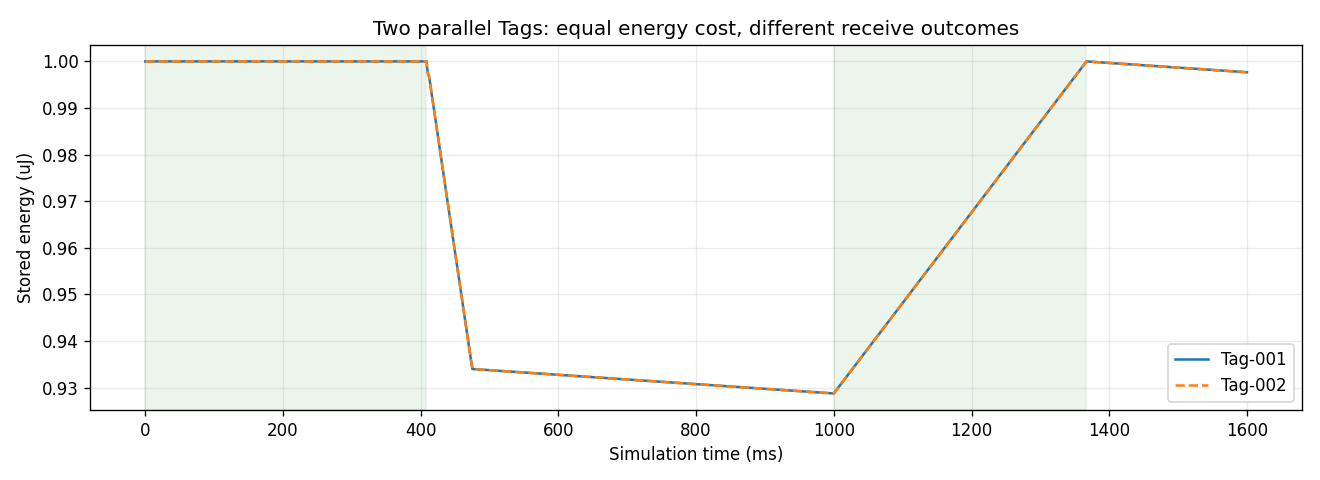

PASS: integer-ns batches, causal current state, parallel completion, persistent energy


In [6]:

figure, axis = plt.subplots(figsize=(11,4))
for tag_id in initial_snapshots:
    history = [row for row in engine.energy_history if row['tag_id']==tag_id]
    axis.plot([row['time_ns']/1e6 for row in history],
              [row['energy_j']*1e6 for row in history],label=tag_id,
              linestyle='-' if tag_id=='Tag-001' else '--')
for window in windows:
    node = window.nodes[0]
    axis.axvspan(node.start_ns/1e6,node.ue_end_ns/1e6,color='green',alpha=0.08)
axis.set(xlabel='Simulation time (ms)',ylabel='Stored energy (uJ)',
         title='Two parallel Tags: equal energy cost, different receive outcomes')
axis.legend()
axis.grid(alpha=0.25)
figure.tight_layout()
plot_buffer = BytesIO()
figure.savefig(plot_buffer,format='png',dpi=120)
display(Image(data=plot_buffer.getvalue()))
plt.close(figure)
print('PASS: integer-ns batches, causal current state, parallel completion, persistent energy')


## 5．邊界與後續接入

此處的事件表屬於環境內部，不能作為 Policy 可讀取的未來觀測。
電量更新只使用剛結束區段的 phase；電量恢復不會自動產生新決策。
耗盡點由 04 解析分段計算，非整數 ns 的 offset 只供診斷，不送入事件佇列。
完整 Access 批次規劃、FBL 抽樣、服務資料認列與 Baseline 尚未接入。
Notebook 04 仍為電量定義來源；此原型尚待人工接受，沒有抽離 src。
